# Notebook 2 — U-Net Baseline: Workflow Guide

## Purpose
Train and evaluate a U-Net-based model on damaged label images and their masks. The split is group-safe: variants derived from the same clean source image should remain in one split.

## Flow
1. Import libraries, check the runtime/GPU, and mount Google Drive.
2. Set dataset/output paths and match damaged images with their masks.
3. Identify each sample's original clean-image group and create train, validation, and test splits by group.
4. Check that source-image groups do not overlap between splits.
5. Copy the data locally where configured and build the TensorFlow input pipeline.
6. Define the U-Net architecture and Dice/IoU metrics.
7. Compile the model, configure checkpoints/callbacks, and train on the training split.
8. Plot training history, evaluate on the held-out test split, and visualize predictions.
9. Save the model and metrics, then perform a final leakage check.

## Before running
Confirm that the dataset path and expected folders are correct, filenames match the pairing assumptions, and the output directory has sufficient space.

## Output
The trained U-Net and experiment outputs are saved to the configured Google Drive paths. Check the relevant save cells for exact filenames.

## Evaluation note
Use validation results for training decisions. Keep the test split held out for final evaluation.


# U-Net Detection — Group-Safe Training

This notebook trains the existing U-Net detector with a leakage-safe split. All damaged variants originating from the same clean image are assigned to exactly one split. Original images, masks, and `dataset_split.csv` are not modified.

**Dataset path:** `IE643-Project/dataset256`  
**Outputs:** `IE643-Project/Reconstruction` and `IE643-Project/results/unet`

Because the previous manifest split individual damaged variants across train/validation/test, retraining is required for a fair evaluation. The architecture and loss remain the same as the previous U-Net notebook.

In [ ]:
# cell 1: import libraries and check gpu
import os
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# cell 2: mount google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# cell 3: set dataset and output paths
dataset_dir = Path('/content/drive/MyDrive/IE643-Project/dataset416')
damaged_dir = dataset_dir / 'damaged'
mask_dir = dataset_dir / 'masks'
clean_dir = dataset_dir / 'clean'
output_dir = Path('/content/drive/MyDrive/IE643-Project/Reconstruction416')
results_dir = Path('/content/drive/MyDrive/IE643-Project/results/unet416')
output_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

print('Dataset exists:', dataset_dir.exists())
print('Damaged exists:', damaged_dir.exists())
print('Masks exists:', mask_dir.exists())
print('Clean exists:', clean_dir.exists())
print('Output directory:', output_dir)
assert damaged_dir.exists() and mask_dir.exists(), 'Check dataset_dir: damaged or masks folder not found.'

Dataset exists: True
Damaged exists: True
Masks exists: True
Clean exists: True
Output directory: /content/drive/MyDrive/IE643-Project/Reconstruction


In [ ]:
# cell 4: match damaged images with masks
image_exts = {'.jpg', '.jpeg', '.png'}
damaged_files = sorted(p for p in damaged_dir.iterdir() if p.is_file() and p.suffix.lower() in image_exts)
mask_files = sorted(p for p in mask_dir.iterdir() if p.is_file() and p.suffix.lower() in image_exts)
mask_dict = {p.stem: p for p in mask_files}
pairs = []
for image_path in damaged_files:
    if image_path.stem in mask_dict:
        pairs.append({'name': image_path.stem,
                      'image': str(image_path),
                      'mask': str(mask_dict[image_path.stem])})

pairs_df = pd.DataFrame(pairs)
print('Damaged images:', len(damaged_files))
print('Masks:', len(mask_files))
print('Matched image-mask pairs:', len(pairs_df))
print('Unmatched damaged images:', len(damaged_files) - len(pairs_df))
assert len(pairs_df) > 0, 'No image-mask pairs found. Check dataset paths and filenames.'
assert pairs_df['name'].is_unique, 'Duplicate damaged image stems found.'

Damaged images: 6794
Masks: 6794
Matched image-mask pairs: 6794
Unmatched damaged images: 0


In [ ]:
# cell 5: assign splits by original clean image id
# The numeric prefix identifies the clean source image for all its damage variants.
df = pairs_df.copy()
df['clean_id'] = df['name'].astype(str).str.extract(r'^(\d+)')[0]
assert df['clean_id'].notna().all(), 'Some filenames do not start with a numeric clean-image ID.'

clean_ids = sorted(df['clean_id'].unique())
train_ids, remaining_ids = train_test_split(clean_ids, test_size=0.30, random_state=seed)
val_ids, test_ids = train_test_split(remaining_ids, test_size=0.50, random_state=seed)

split_map = {image_id: 'train' for image_id in train_ids}
split_map.update({image_id: 'val' for image_id in val_ids})
split_map.update({image_id: 'test' for image_id in test_ids})
df['split'] = df['clean_id'].map(split_map)

train_df = df[df['split'] == 'train'].copy().reset_index(drop=True)
val_df = df[df['split'] == 'val'].copy().reset_index(drop=True)
test_df = df[df['split'] == 'test'].copy().reset_index(drop=True)

print('Total examples:', len(df))
print('Unique clean images:', df['clean_id'].nunique())
print('Examples per split:', df['split'].value_counts().to_dict())
print('Unique clean images per split:', df.groupby('split')['clean_id'].nunique().to_dict())

Total examples: 6794
Unique clean images: 2301
Examples per split: {'train': 4748, 'val': 1023, 'test': 1023}
Unique clean images per split: {'test': 346, 'train': 1610, 'val': 345}


In [ ]:
# cell 6: verify no clean image crosses splits
ids_by_split = {name: set(part['clean_id']) for name, part in [('train', train_df), ('val', val_df), ('test', test_df)]}
print('train-val overlap:', len(ids_by_split['train'] & ids_by_split['val']))
print('train-test overlap:', len(ids_by_split['train'] & ids_by_split['test']))
print('val-test overlap:', len(ids_by_split['val'] & ids_by_split['test']))
assert not (ids_by_split['train'] & ids_by_split['val'])
assert not (ids_by_split['train'] & ids_by_split['test'])
assert not (ids_by_split['val'] & ids_by_split['test'])

split_csv = output_dir / 'unet_group_safe_split.csv'
save_df = df.copy()
save_df['image'] = save_df['image'].apply(lambda x: os.path.relpath(x, dataset_dir))
save_df['mask'] = save_df['mask'].apply(lambda x: os.path.relpath(x, dataset_dir))
save_df.to_csv(split_csv, index=False)
print('Saved new manifest to:', split_csv)
print('The original dataset_split.csv was not changed.')

train-val overlap: 0
train-test overlap: 0
val-test overlap: 0
Saved new manifest to: /content/drive/MyDrive/IE643-Project/Reconstruction/unet_group_safe_split.csv
The original dataset_split.csv was not changed.


In [ ]:
# cell 7: copy image folders locally for faster training
local_dataset = Path('/content/IE643_dataset416(2)')
local_damaged_dir = local_dataset / 'damaged'
local_mask_dir = local_dataset / 'masks'

shutil.copytree(damaged_dir, local_damaged_dir, dirs_exist_ok=True)
shutil.copytree(mask_dir, local_mask_dir, dirs_exist_ok=True)

print('Local damaged images:', len(list(local_damaged_dir.iterdir())))
print('Local masks:', len(list(local_mask_dir.iterdir())))

Local damaged images: 6794
Local masks: 6794


In [ ]:
# cell 8: point split dataframes to local image copies
def local_paths(part):
    part = part.copy()
    part['image'] = part['name'].apply(lambda name: str(local_damaged_dir / f'{name}.jpg'))
    part['mask'] = part['name'].apply(lambda name: str(local_mask_dir / f'{name}.png'))
    missing_images = [p for p in part['image'] if not os.path.exists(p)]
    missing_masks = [p for p in part['mask'] if not os.path.exists(p)]
    if missing_images or missing_masks:
        raise FileNotFoundError(f'Missing images: {missing_images[:3]}; missing masks: {missing_masks[:3]}')
    return part

train_df = local_paths(train_df)
val_df = local_paths(val_df)
test_df = local_paths(test_df)
print('Local paths verified.')
print(train_df[['image', 'mask']].head(2).to_string(index=False))

Local paths verified.
                                                      image                                                      mask
/content/IE643_dataset256(2)/damaged/000000_00_combined.jpg /content/IE643_dataset256(2)/masks/000000_00_combined.png
    /content/IE643_dataset256(2)/damaged/000000_01_blur.jpg     /content/IE643_dataset256(2)/masks/000000_01_blur.png


In [ ]:
# cell 9: define image size and batch size
img_size = 256
batch_size = 4

In [ ]:
# cell 10: load image and binary mask
# This keeps the original notebook's mask convention: any positive mask pixel is foreground.
def load_image_mask(image_path, mask_path):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])

    mask_bytes = tf.io.read_file(mask_path)
    mask = tf.io.decode_image(mask_bytes, channels=1, expand_animations=False)
    mask.set_shape([None, None, 1])

    image = tf.image.resize(image, [img_size, img_size], method='bilinear')
    mask = tf.image.resize(mask, [img_size, img_size], method='nearest')
    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask > 0, tf.float32)
    return image, mask

In [ ]:
# cell 11: build tensorflow datasets
def create_dataset(part, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((part['image'].values, part['mask'].values))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(part), 1000), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)
print('Datasets created.')

Datasets created.


Image batch: (4, 256, 256, 3) range: 0.0 1.0
Mask batch: (4, 256, 256, 1) values: [0. 1.]


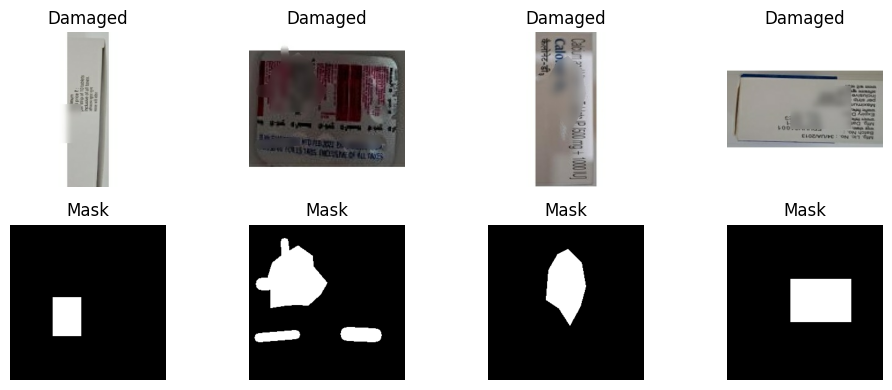

In [ ]:
# cell 12: inspect one training batch
images, masks = next(iter(train_ds))
print('Image batch:', images.shape, 'range:', float(tf.reduce_min(images)), float(tf.reduce_max(images)))
print('Mask batch:', masks.shape, 'values:', np.unique(masks.numpy()))

plt.figure(figsize=(10, 4))
for i in range(min(4, images.shape[0])):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy())
    plt.title('Damaged')
    plt.axis('off')
    plt.subplot(2, 4, i + 5)
    plt.imshow(masks[i, :, :, 0].numpy(), cmap='gray', vmin=0, vmax=1)
    plt.title('Mask')
    plt.axis('off')
plt.tight_layout()
plt.show()

## U-Net architecture

The architecture, optimizer, BCE + Dice loss, and Dice/IoU metrics are retained from the earlier notebook. The key change is the group-safe split.

In [ ]:
# cell 13: define unet convolution block
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x

In [ ]:
# cell 14: define unet model
def unet():
    inputs = layers.Input(shape=(img_size, img_size, 3))
    c1 = conv_block(inputs, 32); p1 = layers.MaxPooling2D()(c1)
    c2 = conv_block(p1, 64); p2 = layers.MaxPooling2D()(c2)
    c3 = conv_block(p2, 128); p3 = layers.MaxPooling2D()(c3)
    c4 = conv_block(p3, 256); p4 = layers.MaxPooling2D()(c4)
    c5 = conv_block(p4, 512)
    u6 = layers.Conv2DTranspose(256, 2, strides=2, padding='same')(c5)
    c6 = conv_block(layers.concatenate([u6, c4]), 256)
    u7 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c6)
    c7 = conv_block(layers.concatenate([u7, c3]), 128)
    u8 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c7)
    c8 = conv_block(layers.concatenate([u8, c2]), 64)
    u9 = layers.Conv2DTranspose(32, 2, strides=2, padding='same')(c8)
    c9 = conv_block(layers.concatenate([u9, c1]), 32)
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c9)
    return keras.Model(inputs, outputs, name='unet_group_safe')

model = unet()
model.summary()

Model: "unet_group_safe"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,873 (29.65 MB)

 Trainable params: 7,765,985 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [ ]:
# cell 15: define dice and iou metrics
def dice_coef(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + 1e-7) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + 1e-7)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_loss(y_true, y_pred):
    return keras.losses.binary_crossentropy(y_true, y_pred) + dice_loss(y_true, y_pred)

def iou(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred = tf.cast(tf.reshape(y_pred, [-1]) > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + 1e-7) / (union + 1e-7)

In [ ]:
# cell 16: compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[dice_coef, iou]
)
print('Model compiled.')

Model compiled.


In [ ]:
# cell 17: configure checkpoints and training callbacks
checkpoint_path = results_dir / 'unet_group_safe_best.keras'
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path), monitor='val_dice_coef', mode='max', save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_dice_coef', mode='max', patience=8, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, verbose=1
    )
]
print('Best checkpoint will be saved to:', checkpoint_path)

Best checkpoint will be saved to: /content/drive/MyDrive/IE643-Project/results/unet/unet_group_safe_best.keras


In [ ]:
# cell 18: train unet on group-safe split
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - dice_coef: 0.2545 - iou: 0.3235 - loss: 1.1643
Epoch 1: val_dice_coef improved from None to 0.50935, saving model to /content/drive/MyDrive/IE643-Project/results/unet/unet_group_safe_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/IE643-Project/results/unet/unet_group_safe_best.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 237s 156ms/step - dice_coef: 0.3539 - iou: 0.4536 - loss: 0.9259 - val_dice_coef: 0.5094 - val_iou: 0.5509 - val_loss: 0.6519 - learning_rate: 1.0000e-04
Epoch 2/30
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - dice_coef: 0.5954 - iou: 0.6545 - loss: 0.5250
Epoch 2: val_dice_coef improved from 0.50935 to 0.75922, saving model to /content/drive/MyDrive/IE643-Project/results/unet/unet_group_safe_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/IE643-Project/results/unet/unet_group_safe_best.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 193s 163ms/step - dice_coef: 0.6644 - iou: 0.7010 - l

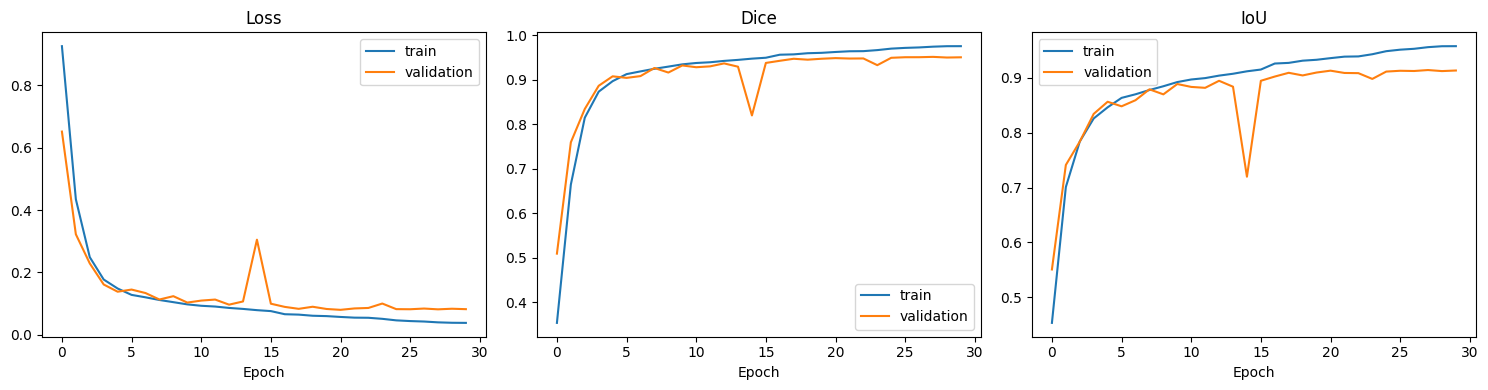

In [ ]:
# cell 19: plot training curves
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ['loss', 'dice_coef', 'iou'], ['Loss', 'Dice', 'IoU']):
    ax.plot(history.history[metric], label='train')
    ax.plot(history.history['val_' + metric], label='validation')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# cell 20: evaluate once on the held-out group-safe test set
# Do not tune model choices based on this test result.
test_results = model.evaluate(test_ds, verbose=1)
print('Test Loss:', test_results[0])
print('Test Dice:', test_results[1])
print('Test IoU:', test_results[2])

256/256 ━━━━━━━━━━━━━━━━━━━━ 15s 57ms/step - dice_coef: 0.9509 - iou: 0.9138 - loss: 0.0813
Test Loss: 0.08134499192237854
Test Dice: 0.9508607387542725
Test IoU: 0.9137762784957886


In [ ]:
# cell 21: visualize test predictions
images, true_masks = next(iter(test_ds))
pred_masks = model.predict(images, verbose=0)
num_show = min(4, int(images.shape[0]))
plt.figure(figsize=(12, 3 * num_show))
for i in range(num_show):
    plt.subplot(num_show, 4, i * 4 + 1)
    plt.imshow(images[i].numpy()); plt.title('Damaged'); plt.axis('off')
    plt.subplot(num_show, 4, i * 4 + 2)
    plt.imshow(true_masks[i, :, :, 0].numpy(), cmap='gray', vmin=0, vmax=1); plt.title('Ground truth'); plt.axis('off')
    plt.subplot(num_show, 4, i * 4 + 3)
    plt.imshow((pred_masks[i, :, :, 0] > 0.5), cmap='gray', vmin=0, vmax=1); plt.title('Predicted'); plt.axis('off')
    plt.subplot(num_show, 4, i * 4 + 4)
    plt.imshow(images[i].numpy())
    plt.imshow((pred_masks[i, :, :, 0] > 0.5), cmap='Reds', alpha=0.4, vmin=0, vmax=1)
    plt.title('Overlay'); plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# cell 22: save group-safe detector and metrics
model_save_path = results_dir / 'unet_group_safe_best.keras'
model.save(model_save_path)
results = pd.DataFrame({
    'model': ['U-Net group-safe'],
    'test_loss': [float(test_results[0])],
    'test_dice': [float(test_results[1])],
    'test_iou': [float(test_results[2])],
    'split_manifest': [str(split_csv)]
})
metrics_path = results_dir / 'unet_group_safe_results.csv'
results.to_csv(metrics_path, index=False)
print('Model saved:', model_save_path)
print('Metrics saved:', metrics_path)
print(results.to_string(index=False))

Model saved: /content/drive/MyDrive/IE643-Project/results/unet/unet_group_safe_best.keras
Metrics saved: /content/drive/MyDrive/IE643-Project/results/unet/unet_group_safe_results.csv
           model  test_loss  test_dice  test_iou                                                                split_manifest
U-Net group-safe   0.081345   0.950861  0.913776 /content/drive/MyDrive/IE643-Project/Reconstruction/unet_group_safe_split.csv


In [ ]:
# cell 23: final leakage check from the saved manifest
saved_df = pd.read_csv(split_csv)
leak_count = int((saved_df.groupby('clean_id')['split'].nunique() > 1).sum())
print('Clean IDs crossing splits:', leak_count)
assert leak_count == 0, 'Leakage check failed.'
print('Group-safe split verified.')

Clean IDs crossing splits: 0
Group-safe split verified.
